In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

# Load the dataset
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

TensorFlow version: 2.21.0
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


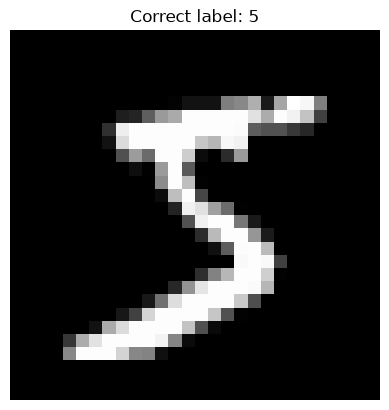

Image shape: (28, 28)
Pixel data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In [2]:
index = 0

plt.imshow(x_train[index], cmap="gray")
plt.title(f"Correct label: {y_train[index]}")
plt.axis("off")
plt.show()

print("Image shape:", x_train[index].shape)
print("Pixel data type:", x_train[index].dtype)
print("Minimum pixel value:", x_train[index].min())
print("Maximum pixel value:", x_train[index].max())

In [3]:
# Shuffle the original training examples reproducibly
rng = np.random.default_rng(42)
indices = rng.permutation(len(x_train))

x_train = x_train[indices]
y_train = y_train[indices]

# Reserve 6,000 examples for validation
x_val = x_train[:6000]
y_val = y_train[:6000]

x_train = x_train[6000:]
y_train = y_train[6000:]

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add one channel for grayscale images
x_train = x_train[..., np.newaxis]
x_val = x_val[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Testing:", x_test.shape, y_test.shape)

Training: (54000, 28, 28, 1) (54000,)
Validation: (6000, 28, 28, 1) (6000,)
Testing: (10000, 28, 28, 1) (10000,)


In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        32, kernel_size=3,
        padding="same", activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=2),

    tf.keras.layers.Conv2D(
        64, kernel_size=3,
        padding="same", activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64, activation="relu"),

    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,234 (860.29 KB)

 Trainable params: 220,234 (860.29 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [8]:
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=5,
    batch_size=128
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.9317 - loss: 0.2296 - val_accuracy: 0.9788 - val_loss: 0.0797
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.9808 - loss: 0.0634 - val_accuracy: 0.9828 - val_loss: 0.0587
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9859 - loss: 0.0457 - val_accuracy: 0.9820 - val_loss: 0.0575
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.9898 - loss: 0.0338 - val_accuracy: 0.9873 - val_loss: 0.0420
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - accuracy: 0.9926 - loss: 0.0261 - val_accuracy: 0.9858 - val_loss: 0.0467


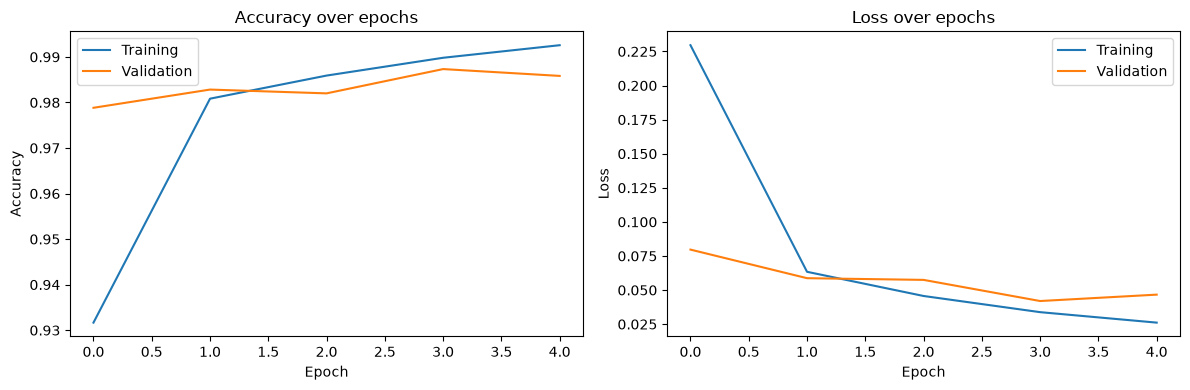

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy over epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss over epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [10]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=2
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

313/313 - 1s - 5ms/step - accuracy: 0.9893 - loss: 0.0315
Test loss: 0.0315
Test accuracy: 0.9893


In [11]:
model.save("digitvision_cnn.keras")

In [12]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

model = tf.keras.models.load_model("digitvision_cnn.keras")

print("Model loaded successfully!")

Model loaded successfully!


In [13]:
index = 0

image = x_test[index]       # Shape: (28, 28, 1)
true_label = y_test[index]  # Correct digit

# Add a batch dimension: (28, 28, 1) -> (1, 28, 28, 1)
image_batch = np.expand_dims(image, axis=0)

# Predict probabilities for all 10 digit classes
probabilities = model.predict(image_batch, verbose=0)[0]

predicted_digit = np.argmax(probabilities)
confidence = probabilities[predicted_digit]

print("Actual digit:", true_label)
print("Predicted digit:", predicted_digit)
print(f"Model confidence: {confidence:.2%}")

Actual digit: 7
Predicted digit: 7
Model confidence: 100.00%


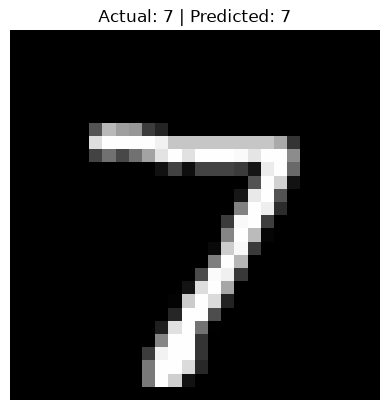

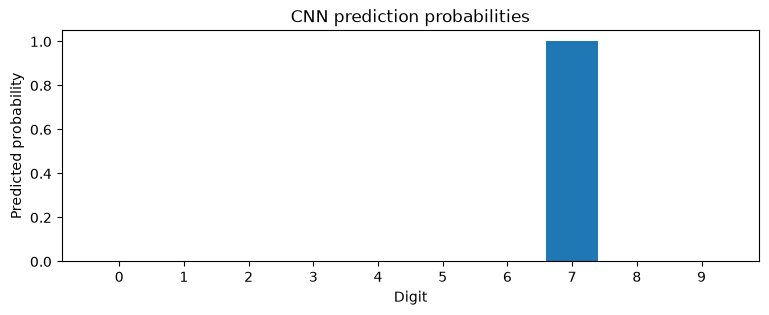

In [14]:
plt.imshow(x_test[index].squeeze(), cmap="gray")

plt.title(
    f"Actual: {true_label} | Predicted: {predicted_digit}"
)
plt.axis("off")
plt.show()

plt.figure(figsize=(9, 3))
plt.bar(range(10), probabilities)
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Predicted probability")
plt.title("CNN prediction probabilities")
plt.show()

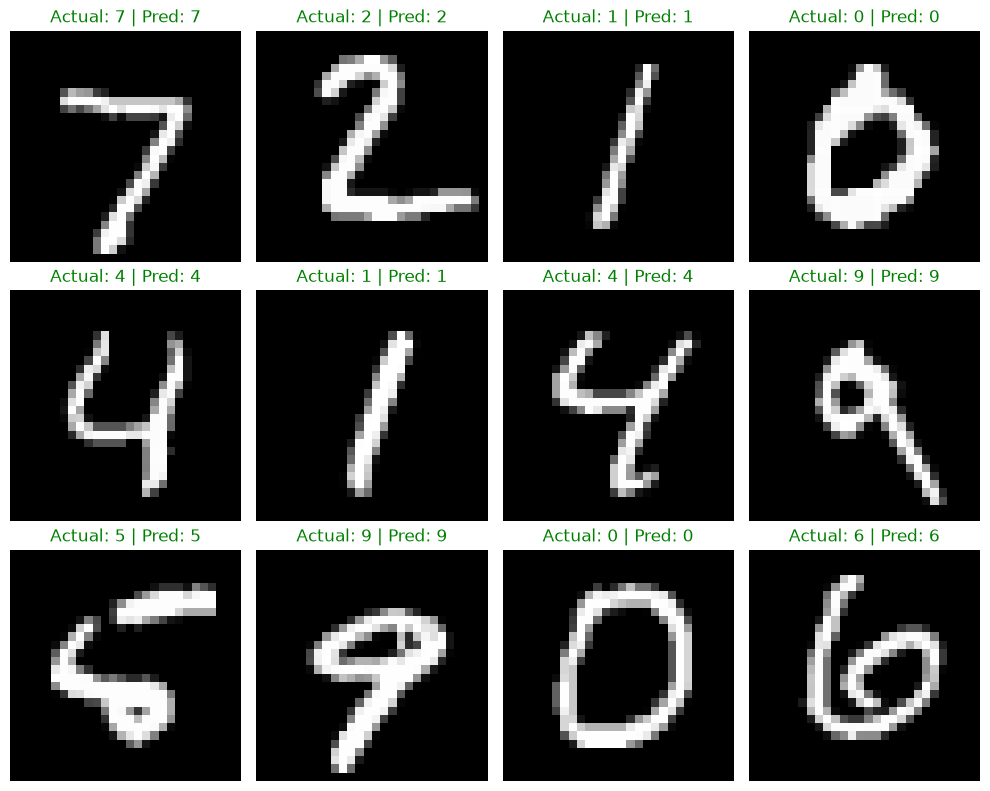

In [15]:
indices = np.arange(12)

images_batch = x_test[indices]
probabilities_batch = model.predict(
    images_batch,
    verbose=0
)

predictions = np.argmax(probabilities_batch, axis=1)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for i, ax in enumerate(axes.flat):
    actual = y_test[indices[i]]
    predicted = predictions[i]

    ax.imshow(x_test[indices[i]].squeeze(), cmap="gray")
    ax.set_title(
        f"Actual: {actual} | Pred: {predicted}",
        color="green" if actual == predicted else "red"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Load the saved model if it isn't already loaded
model = tf.keras.models.load_model("digitvision_cnn.keras")

# Predict all test images
probabilities = model.predict(x_test, batch_size=128, verbose=1)

# Select the digit with the highest predicted probability
y_pred = np.argmax(probabilities, axis=1)

print("Actual labels:", y_test.shape)
print("Predicted labels:", y_pred.shape)
print("First 10 predictions:", y_pred[:10])
print("First 10 actual labels:", y_test[:10])

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
Actual labels: (10000,)
Predicted labels: (10000,)
First 10 predictions: [7 2 1 0 4 1 4 9 5 9]
First 10 actual labels: [7 2 1 0 4 1 4 9 5 9]


In [17]:
cm = tf.math.confusion_matrix(
    labels=y_test,
    predictions=y_pred,
    num_classes=10
).numpy()

print(cm)

[[ 977    0    0    0    0    0    1    1    1    0]
 [   0 1133    0    0    0    0    2    0    0    0]
 [   3    3 1008    0    6    0    0   10    1    1]
 [   1    0    1 1000    0    3    0    2    3    0]
 [   0    1    0    0  979    0    1    0    0    1]
 [   2    0    0    6    0  875    2    2    4    1]
 [   3    2    0    0    1    1  949    0    2    0]
 [   0    3    0    1    0    0    0 1022    1    1]
 [   3    0    1    1    0    0    1    0  962    6]
 [   3    3    0    0    5    3    0    5    2  988]]


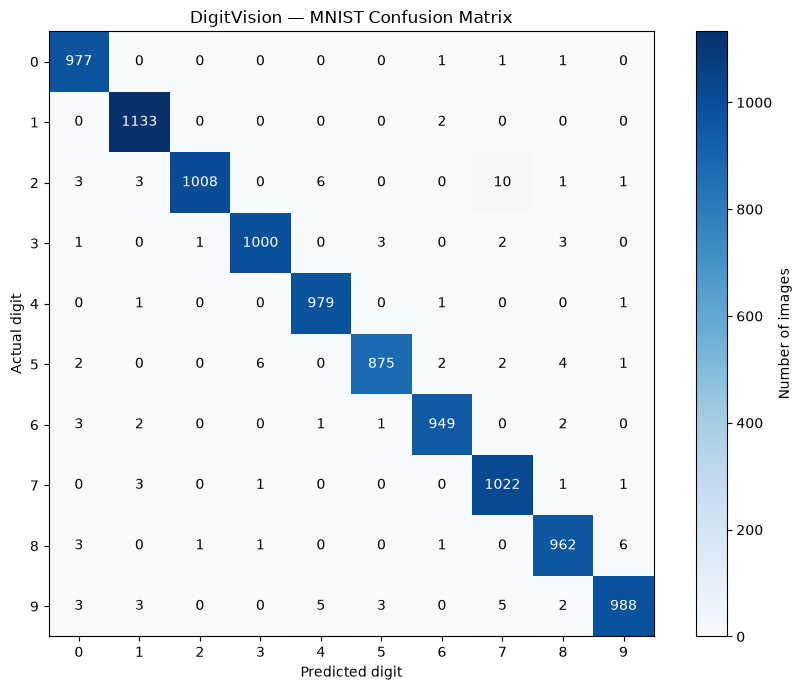

In [18]:
fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(cm, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of images")

ax.set(
    xlabel="Predicted digit",
    ylabel="Actual digit",
    title="DigitVision — MNIST Confusion Matrix"
)

ax.set_xticks(range(10))
ax.set_yticks(range(10))

# Display the count inside each cell
threshold = cm.max() / 2

for row in range(10):
    for col in range(10):
        ax.text(
            col,
            row,
            str(cm[row, col]),
            ha="center",
            va="center",
            color="white" if cm[row, col] > threshold else "black"
        )

plt.tight_layout()
plt.show()

In [19]:
correct_per_digit = np.diag(cm)
actual_per_digit = cm.sum(axis=1)

recall_per_digit = correct_per_digit / actual_per_digit

for digit in range(10):
    print(
        f"Digit {digit}: "
        f"{correct_per_digit[digit]}/{actual_per_digit[digit]} correct "
        f"({recall_per_digit[digit]:.2%} recall)"
    )

Digit 0: 977/980 correct (99.69% recall)
Digit 1: 1133/1135 correct (99.82% recall)
Digit 2: 1008/1032 correct (97.67% recall)
Digit 3: 1000/1010 correct (99.01% recall)
Digit 4: 979/982 correct (99.69% recall)
Digit 5: 875/892 correct (98.09% recall)
Digit 6: 949/958 correct (99.06% recall)
Digit 7: 1022/1028 correct (99.42% recall)
Digit 8: 962/974 correct (98.77% recall)
Digit 9: 988/1009 correct (97.92% recall)


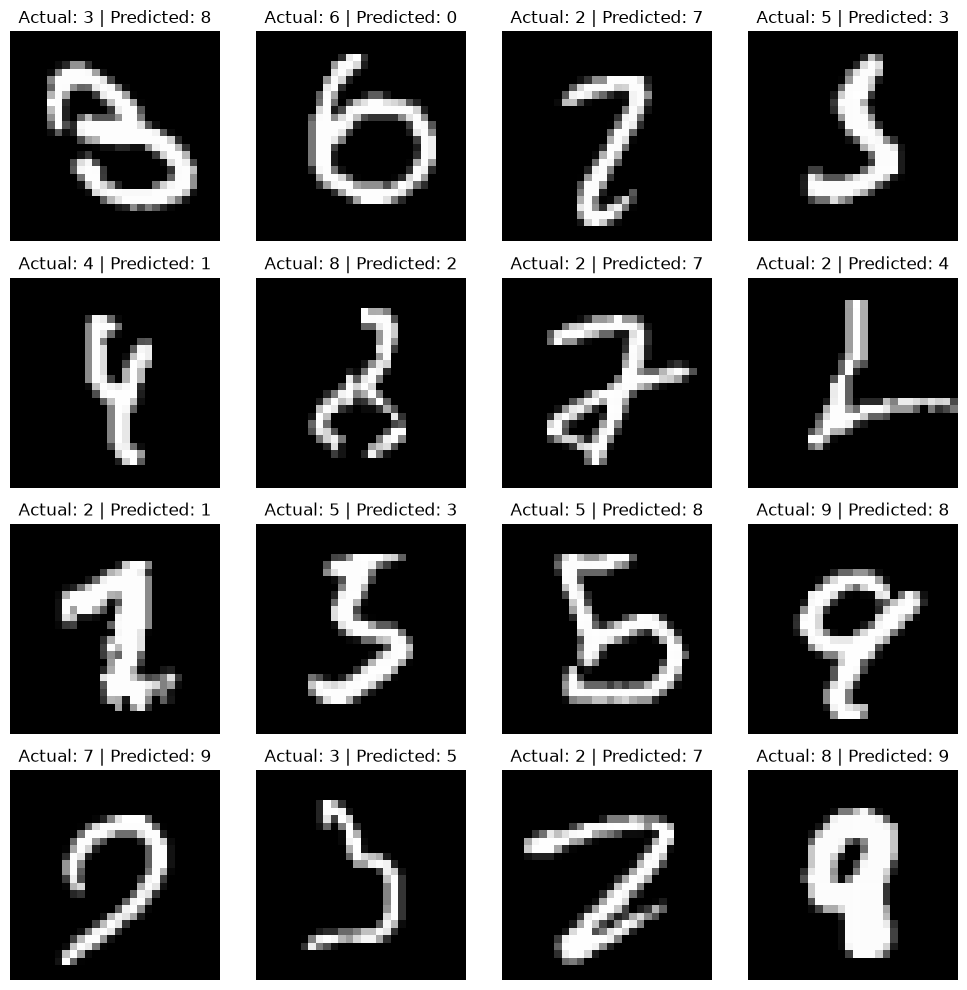

In [21]:
wrong_indices = np.where(y_pred != y_test)[0]
n_show = min(16, len(wrong_indices))

if n_show > 0:
    fig, axes = plt.subplots(4, 4, figsize=(10, 10))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        if i < n_show:
            idx = wrong_indices[i]

            ax.imshow(x_test[idx].squeeze(), cmap="gray")
            ax.set_title(
                f"Actual: {y_test[idx]} | Predicted: {y_pred[idx]}"
            )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions found.")

In [22]:
# Copy the matrix so we don't modify the original
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)

# Find the cell with the highest number of mistakes
actual_digit, predicted_digit = np.unravel_index(
    np.argmax(off_diagonal),
    off_diagonal.shape
)

mistake_count = off_diagonal[actual_digit, predicted_digit]

if mistake_count > 0:
    print(
        f"The most frequent confusion is actual digit {actual_digit} "
        f"predicted as {predicted_digit}: {mistake_count} images."
    )
else:
    print("No incorrect predictions found.")

The most frequent confusion is actual digit 2 predicted as 7: 10 images.
